In [1]:
import os
import numpy as np
import librosa
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
from tensorflow.keras.utils import plot_model

In [2]:
non_music_path = "dataset2/non_music"
music_path = "dataset2/music"

In [3]:
non_music_files = [os.path.join(non_music_path, f) for f in os.listdir(non_music_path)]
music_files = [os.path.join(music_path, f) for f in os.listdir(music_path)]

In [4]:
def extract_features(file_path):
    audio, sr = librosa.load(file_path)
    # Extract features like MFCCs, chroma features, etc.
    # For simplicity, let's use only MFCCs for this example
    mfccs = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=20)
    return mfccs.flatten()

In [5]:
non_music_features = np.array([extract_features(f) for f in non_music_files])

In [6]:

music_features = np.array([extract_features(f) for f in music_files])

In [7]:
test_music_path ="dataset2/test/music"
test_music_files=[os.path.join(test_music_path,f)for f in os.listdir(test_music_path)]
test_non_music_path ="dataset2/test/non_music"
test_non_music_files=[os.path.join(test_non_music_path,f)for f in os.listdir(test_non_music_path)]

In [8]:
test_music_features= np.array([extract_features(f) for f in test_music_files])
test_non_music_features= np.array([extract_features(f) for f in test_non_music_files])

In [9]:
non_music_labels = np.zeros(len(non_music_files))
music_labels = np.ones(len(music_files))
test_non_music_labels = np.zeros(len(test_non_music_files))
test_music_labels = np.ones(len(test_music_files))

In [10]:
X = np.concatenate((non_music_features, music_features))
y = np.concatenate((non_music_labels, music_labels))

In [11]:
X_train=X
X_test= np.concatenate((test_non_music_features, test_music_features))
y_train=y 
y_test =np.concatenate((test_non_music_labels, test_music_labels))

In [12]:
n=X_train.shape[1]
print(n)

4320


In [13]:
model = Sequential([
    Flatten(input_shape=(X_train.shape[1],)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

In [14]:
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

In [15]:
model.fit(X_train, y_train, epochs=10, batch_size=32, validation_split=0.2)

Epoch 1/10
2250/2250 [==============================] - 21s 5ms/step - loss: 0.5714 - accuracy: 0.9410 - val_loss: 0.7917 - val_accuracy: 0.8113
Epoch 2/10
2250/2250 [==============================] - 9s 4ms/step - loss: 0.1285 - accuracy: 0.9508 - val_loss: 0.3967 - val_accuracy: 0.8222
Epoch 3/10
2250/2250 [==============================] - 9s 4ms/step - loss: 0.1220 - accuracy: 0.9561 - val_loss: 0.4734 - val_accuracy: 0.6167
Epoch 4/10
2250/2250 [==============================] - 11s 5ms/step - loss: 0.1221 - accuracy: 0.9575 - val_loss: 0.4352 - val_accuracy: 0.7944
Epoch 5/10
2250/2250 [==============================] - 11s 5ms/step - loss: 0.1055 - accuracy: 0.9609 - val_loss: 0.4270 - val_accuracy: 0.7945
Epoch 6/10
2250/2250 [==============================] - 11s 5ms/step - loss: 0.0961 - accuracy: 0.9641 - val_loss: 0.4066 - val_accuracy: 0.7686
Epoch 7/10
2250/2250 [==============================] - 11s 5ms/step - loss: 0.0917 - accuracy: 0.9662 - val_loss: 0.3100 - val_accu

In [16]:
y_pred = (model.predict(X_test) > 0.9).astype("int32")
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

313/313 [==============================] - 1s 2ms/step
Accuracy: 0.8992


In [17]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

         0.0       0.90      0.89      0.90      5000
         1.0       0.90      0.90      0.90      5000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



In [18]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percent = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis] * 100

print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[4470  530]
 [ 478 4522]]


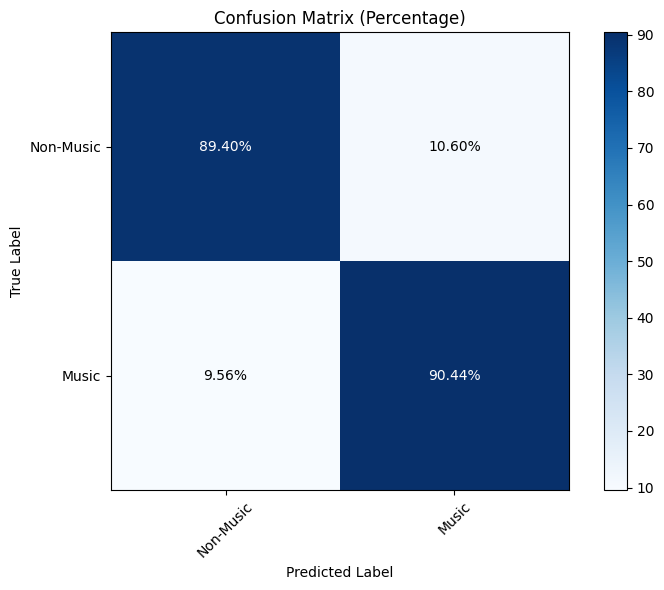

In [19]:
plt.figure(figsize=(8, 6))
plt.imshow(conf_matrix_percent, cmap=plt.cm.Blues)
plt.title('Confusion Matrix (Percentage)')
plt.colorbar()

classes = ['Non-Music', 'Music']
tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes, rotation=45)
plt.yticks(tick_marks, classes)

thresh = conf_matrix_percent.max() / 2.
for i, j in np.ndindex(conf_matrix_percent.shape):
    plt.text(j, i, format(conf_matrix_percent[i, j], '.2f') + '%',
             ha="center", va="center",
             color="white" if conf_matrix_percent[i, j] > thresh else "black")

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('ConfusionMatrixCNN')
plt.show()

ModuleNotFoundError: No module named 'pydot'

In [24]:
output_model_path = "CNN_model_architecture_2.png"
plot_model(model, to_file=output_model_path, show_shapes=True, show_layer_names=True)

You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model to work.


In [25]:
model.save("CNNmodelForMp3_100k_v1.h5")